<div style="border-bottom:2px solid #0077c8;padding:12px 0 24px;margin-bottom:24px;">
<p style="color:#0077c8;letter-spacing:.1em;font-size:12px;margin-top:24px;">DSPRO2 · TEAM 6</p>
<h1 style="font-family:'Arial Narrow',sans-serif;font-weight:800;line-height:1.05;">PREDICTING PURCHASE<br>PRICES IN SWITZERLAND</h1>
<p style="font-size:17px;color:#153652;margin-top:8px;">The rent pipeline applied to flats and houses for sale</p>
<p>Elias Martinelli · Timo Schlumpf</p>
</div>

## 0. Purpose and Scope

The Comparis scrape contains about as many objects **for sale** as for rent. This notebook
transfers the rent pipeline (`dspro2_ml_pipeline_comparis.ipynb`) to asking purchase prices.
It is an **extension outside the pre-registered evaluation plan**: the decisions here are
exploratory, the test set is still used once per model, and nothing feeds back into RQ1–RQ4.

| Section | Content |
|---|---|
| 1–3 | setup, purchase objects from `comparis_cleaned.db`, features |
| 4–6 | frozen split, naive CHF/m² baseline, LightGBM with and without location (target encoding) |
| 7 | text and portal attributes |
| 8 | calibrated 80 % intervals (monotone quantile LightGBM + Mondrian CQR) |
| 9–11 | SHAP, error analysis by segment, model bundle and summary |

**Data.** `comparis_cleaning.ipynb` keeps flats and houses for sale with a total price and
coordinates, deduplicates them (`buy_…` object ids), assigns the geo hierarchy, enriches them
like the rentals (GWR, ARE, BFE, STATPOP) and applies the purchase domain rules: **price CHF
50,000–30,000,000** (lower prices are placeholders, symbolic prices or parking spaces), living
area 15–2,000 m², rooms 1–15. CHF/m² outliers are flagged there and removed here.

`DSPRO2_RUN_MODE=fast` lowers all budgets for a smoke run.

## 1. Setup

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # optuna imports tqdm.auto

In [2]:
import logging
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from rentml import comparis, data, evaluation, geo, intervals, models, text
from rentml.config import (
    FIGURES,
    INTERIM,
    INTERVAL_COVERAGE,
    MIN_MONDRIAN_GROUP,
    MODELS,
    QUANTILE_LEVELS,
    RANDOM_STATE,
    RESULTS,
    ensure_dirs,
)
from rentml.evaluation import COLORS, chf_formatter

In [3]:
RUN_MODE = os.environ.get("DSPRO2_RUN_MODE", "full")
FAST = RUN_MODE == "fast"
BUDGET = {"optuna_trials": 6 if FAST else 60, "cv_folds": 3 if FAST else 5,
          "n_boot": 300 if FAST else 2000, "shap_rows": 300 if FAST else 2000}
SESSION_ID = pd.Timestamp.now().strftime("%Y%m%d-%H%M%S")
EXPERIMENT = "dspro2-buy-fast" if FAST else "dspro2-buy"
DATA_USED = "comparis"
RESULTS_DIR, FIG_SUBDIR = RESULTS / "buy", "buy"
BUNDLE_PATH = MODELS / "buy_bundle_v1.joblib"
ensure_dirs()
for folder in (RESULTS_DIR, FIGURES / FIG_SUBDIR):
    folder.mkdir(parents=True, exist_ok=True)
logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("mlflow", "alembic", "urllib3", "matplotlib", "fontTools", "optuna"):
    logging.getLogger(noisy).setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
evaluation.apply_plot_style()
MCHF = plt.FuncFormatter(lambda v, _: f"{v / 1e6:,.1f} M")
print(f"run {RUN_MODE}, session {SESSION_ID}")


def save_fig(fig: plt.Figure, name: str) -> tuple:
    return evaluation.save_fig(fig, f"{FIG_SUBDIR}/{name}")


def write_table(df: pd.DataFrame, name: str, fmt: dict | str = "g",
                note: str | None = None) -> None:
    cols = list(df.columns)
    floatfmt = fmt if isinstance(fmt, str) else tuple(fmt.get(c, "g") for c in cols)
    head = f"<!-- {note} -->\n" if note else ""
    md_table = df.astype(object).where(df.notna(), None).to_markdown(
        index=False, floatfmt=floatfmt, missingval="–")
    (RESULTS_DIR / f"{name}.md").write_text(head + md_table + "\n")


def track(name: str, stage: str, metrics: dict, params: dict | None = None) -> None:
    finite = {k: float(v) for k, v in metrics.items() if v is not None and np.isfinite(v)}
    evaluation.log_run(name, stage, params=params, metrics=finite, experiment=EXPERIMENT,
                       tags={"session": SESSION_ID, "data_source": DATA_USED})


def metrics_row(y: np.ndarray, pred: np.ndarray) -> dict[str, float]:
    ape = np.abs(pred - y) / y
    return evaluation.regression_metrics(y, pred) | {"MdAPE": 100 * float(np.median(ape)),
                                                     "within_10pct": float(np.mean(ape <= 0.10))}

run full, session 20261108-193154


## 2. Purchase Objects

One row per object (median price over its listings). The CHF/m² outliers flagged in the cleaning
notebook are set aside and only scored in the error analysis.

In [4]:
buy = comparis.load_cleaned("buy")
log = comparis.load_cleaned("cleaning_log")
display(log[log["analysis"].isin(["all", "buy"])])
df_all = buy.join(geo.nested_group_keys(buy))
df_outliers = df_all[df_all["ppsqm_outlier"]].copy()
df = df_all[~df_all["ppsqm_outlier"]].copy()
overview = (df.assign(chf_m2=df["price"] / df["area"])
            .groupby("property_category")
            .agg(objects=("price", "size"), median_price=("price", "median"),
                 p10_price=("price", lambda s: s.quantile(0.1)),
                 p90_price=("price", lambda s: s.quantile(0.9)),
                 median_area=("area", "median"), median_chf_m2=("chf_m2", "median"),
                 egid_found=("egid", lambda s: s.notna().mean()),
                 area_from_gwr=("area_source", lambda s: s.eq("gwr").mean())))
write_table(overview.reset_index(), "buy_overview", ".3g")
display(overview.round(2))
print(f"{len(df):,} objects in the model table, {len(df_outliers):,} CHF/m² outliers set aside")

,analysis,step,n_rows,removed,retained_pct
0,all,raw listings,65552,0,100.0
6,buy,flats and houses for sale with total price and...,39667,0,60.5
7,buy,one row per object (dedup),35801,3866,54.6
8,buy,admin match in Switzerland,35801,0,54.6
9,buy,"domain rules (price >= 50k, area, rooms)",28476,7325,43.4
10,buy,of which without CHF/m² outlier,27793,683,42.4


,objects,median_price,p10_price,p90_price,median_area,median_chf_m2,egid_found,area_from_gwr
property_category,,,,,,,,
apartment,17692,845000.0,440000.0,2014500.0,109.0,7993.19,0.48,0.02
house,10101,1290000.0,650000.0,3180000.0,171.0,7596.90,0.47,0.05


27,793 objects in the model table, 683 CHF/m² outliers set aside


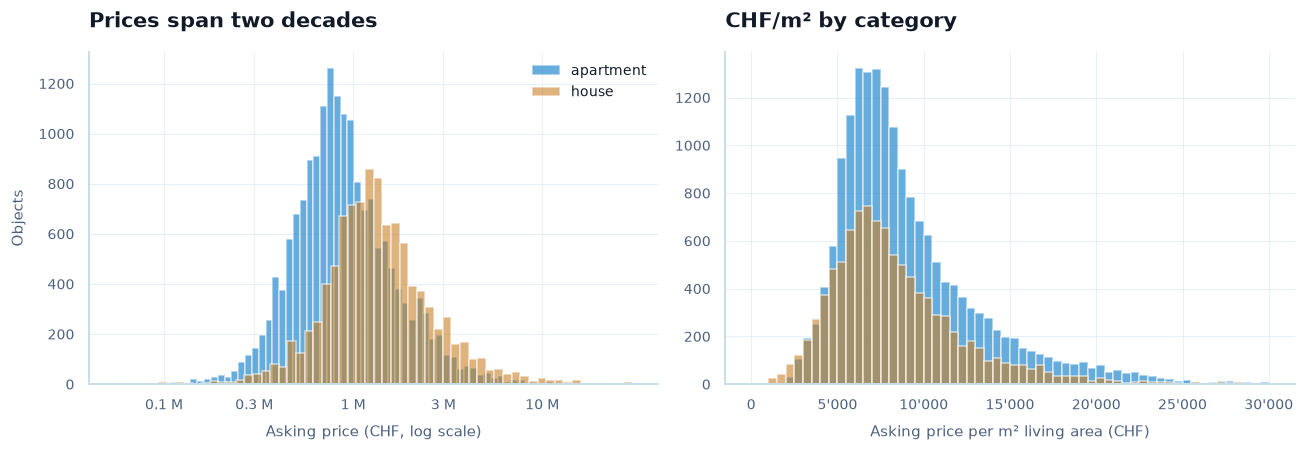

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cat_colors = {"apartment": COLORS["primary"], "house": COLORS["orange"]}
for cat, part in df.groupby("property_category"):
    axes[0].hist(np.log10(part["price"]), bins=60, alpha=0.6, color=cat_colors[cat], label=cat)
    axes[1].hist(part["price"] / part["area"], bins=np.linspace(0, 30000, 61), alpha=0.6,
                 color=cat_colors[cat], label=cat)
ticks = [1e5, 3e5, 1e6, 3e6, 1e7]
axes[0].set_xticks(np.log10(ticks), [f"{t / 1e6:g} M" for t in ticks])
axes[0].set(xlabel="Asking price (CHF, log scale)", ylabel="Objects",
            title="Prices span two decades")
axes[1].xaxis.set_major_formatter(chf_formatter())
axes[1].set(xlabel="Asking price per m² living area (CHF)", title="CHF/m² by category")
axes[0].legend()
fig.tight_layout()
save_fig(fig, "buy_price_distribution")
plt.show()

**Interpretation.** Houses are larger and dearer in absolute terms but not per m²; the log scale
makes the target roughly symmetric, so all models are trained on `log(price)` and evaluated in
CHF. Because absolute errors grow with the price, the **median absolute percentage error
(MdAPE)** and the share of estimates within ±10 % are reported next to the MAE.

## 3. Features

The rent features (`F_TAB`: area, rooms, building and location) plus purchase-specific ones:
`is_house`, the plot area of the listing (`plot_area`, mostly houses), floor, renovation year,
balconies, `area_from_gwr` and the portal `has_*`/`is_*` flags with at least 1 % prevalence
(`F_PORTAL`). Location enters as LV95 and rotated coordinates plus target encodings of canton,
district and municipality (`GROUP_COLS`), exactly as in the rent model.

In [6]:
df = data.add_engineered_features(df)
df["log_price"] = np.log(df["price"])
df["is_house"] = df["property_category"].eq("house").astype(float)
df["area_from_gwr"] = df["area_source"].eq("gwr").astype(float)
ROOMS_INTEGER_ONLY = bool((df["rooms"].dropna() % 1 == 0).all())
F_TAB = [c for c in data.BASE + data.BUILDING + data.LOCATION
         if not (c == "rooms_is_integer" and ROOMS_INTEGER_ONLY)] + ["is_house", "plot_area"]
PORTAL_FLAGS = sorted(c for c in df if c.startswith(("has_", "is_"))
                      and c not in ("is_house", "is_flat_share") and df[c].mean() >= 0.01)
F_PORTAL = ["floor", "renovation_year", "balcony_count", "area_from_gwr", *PORTAL_FLAGS]
COORDS = data.COORDS
F_GEO = F_TAB + COORDS + data.ROT_COORDS
GROUP_COLS = ["re_canton", "re_district", "re_municipality"]
TE_INPUT = F_GEO + GROUP_COLS
MONOTONE_INCREASING = ("area", "area_per_room")
missing = df[F_TAB + F_PORTAL].isna().mean().mul(100).round(1)
display(missing[missing > 0].sort_values(ascending=False).rename("missing %").to_frame().T)
print(f"F_TAB ({len(F_TAB)}): {F_TAB}\nF_PORTAL ({len(F_PORTAL)})")

,plot_area,renovation_year,land_area_per_apartment,apartments,solar,land_area,population,oev,elevation,floor,building_age,year_built,area_per_room,rooms_is_integer,rooms
missing %,76.5,74.1,59.6,59.5,58.6,52.1,46.7,42.0,41.5,34.8,12.3,12.3,2.0,2.0,2.0


F_TAB (17): ['area', 'rooms', 'area_per_room', 'rooms_is_integer', 'year_built', 'building_age', 'apartments', 'land_area', 'land_area_per_apartment', 'population', 'oev', 'solar', 'elevation', 'muni_density', 'muni_population', 'is_house', 'plot_area']
F_PORTAL (28)


## 4. Frozen Split and Folds

60 % train, 20 % calibration (intervals only), 20 % test; grouped by object and stratified by
canton × price quartile with the functions of the rent pipeline. The split is stored in
`data/interim/split_buy_v1.parquet` and reused while the set of objects does not change.

In [7]:
strata = data.make_strata(df)
split_col = data.train_calib_test_split(df, strata)
split_file = INTERIM / "split_buy_v1.parquet"
if split_file.is_file():
    frozen = pd.read_parquet(split_file)["split"]
    if frozen.index.sort_values().equals(df.index.sort_values()):
        split_col = frozen
split_col.rename_axis("listing_id").to_frame().to_parquet(split_file)
df["split"] = split_col.reindex(df.index)
train_df, calib_df, test_df = (df[df["split"].eq(s)] for s in ("train", "calib", "test"))
y_train, y_calib, y_test = (f["price"].to_numpy() for f in (train_df, calib_df, test_df))
y_train_log = np.log(y_train)
cv_folds = data.grouped_cv_folds(train_df, strata, n_splits=BUDGET["cv_folds"])
display(df.groupby("split").agg(n=("price", "size"), median_price=("price", "median"),
                                house_share=("is_house", "mean"), cantons=("canton", "nunique"))
        .loc[["train", "calib", "test"]].round(3))

,n,median_price,house_share,cantons
split,,,,
train,16675,985000.0,0.359,26
calib,5559,980000.0,0.371,25
test,5559,982500.0,0.369,25


## 5. Baselines: Naive CHF/m² and LightGBM Without Location

The **naive baseline** is the broker's rule of thumb: median CHF/m² of the municipality (else
district, canton, Switzerland below 5 training objects) times the living area, fitted separately
for flats and houses. **LightGBM-tab** uses `F_TAB` without any location signal.

In [8]:
pred_test: dict[str, np.ndarray] = {}
pred_calib: dict[str, np.ndarray] = {}
cv_oof: dict[str, np.ndarray] = {}


def naive_by_category(fit_df: pd.DataFrame, apply_df: pd.DataFrame) -> np.ndarray:
    out = pd.Series(np.nan, index=apply_df.index)
    for cat, part in fit_df.groupby("property_category"):
        model = models.NaiveMunicipalityBaseline().fit(part, part["price"].to_numpy())
        rows = apply_df["property_category"].eq(cat)
        out[rows] = model.predict(apply_df[rows])
    return out.to_numpy()


pred_test["naive"] = naive_by_category(train_df, test_df)
pred_calib["naive"] = naive_by_category(train_df, calib_df)
cv_oof["naive"] = np.full(len(train_df), np.nan)
for tr, va in cv_folds:
    cv_oof["naive"][va] = naive_by_category(train_df.iloc[tr], train_df.iloc[va])

def lgb_tab() -> object:
    return models.make_lgbm(None, models.monotone_vector(F_TAB, MONOTONE_INCREASING))


cv_oof["lgbm_tab"] = np.exp(models.fit_predict_cv(lgb_tab, train_df[F_TAB], y_train_log, cv_folds))
model_tab = lgb_tab().fit(train_df[F_TAB], y_train_log)
pred_test["lgbm_tab"] = np.exp(model_tab.predict(test_df[F_TAB]))
pred_calib["lgbm_tab"] = np.exp(model_tab.predict(calib_df[F_TAB]))
for name in ("naive", "lgbm_tab"):
    track(name, "baseline", {"cv_mae": evaluation.METRICS["MAE"](y_train, cv_oof[name])}
          | {f"test_{k.lower()}": v for k, v in metrics_row(y_test, pred_test[name]).items()})
display(pd.DataFrame({n: metrics_row(y_test, pred_test[n]) for n in pred_test}).T.round(3))

,MAE,RMSE,MedAE,MAPE,R2,MdAPE,within_10pct
naive,319891.836,680429.858,163508.772,23.624,0.737,16.692,0.329
lgbm_tab,326602.940,710692.853,163202.508,23.180,0.713,17.312,0.308


## 6. LightGBM with Coordinates and Target Encoding

The rent model's best conventional location model: LV95 and 45°-rotated coordinates plus
cross-fitted target encodings of canton, district and municipality, monotone in the living area,
tuned with Optuna on the grouped folds (mean CV MAE in CHF).

In [9]:
def te_lgbm(params: dict | None = None) -> object:
    return models.make_te_lgbm(F_GEO, GROUP_COLS, params, MONOTONE_INCREASING)


lgb_params, study = models.tune_lgbm_optuna(train_df[TE_INPUT], y_train_log, cv_folds,
                                            n_trials=BUDGET["optuna_trials"],
                                            model_factory=te_lgbm, seed=RANDOM_STATE)
cv_oof["lgbm_te"] = np.exp(models.fit_predict_cv(lambda: te_lgbm(lgb_params), train_df[TE_INPUT],
                                                 y_train_log, cv_folds))
encoder = te_lgbm(lgb_params)[:-1]
X_train = encoder.fit_transform(train_df[TE_INPUT], y_train_log)
X_calib, X_test = encoder.transform(calib_df), encoder.transform(test_df)
F_LGB = list(X_train.columns)
lgb_point = models.make_lgbm(lgb_params, models.monotone_vector(F_LGB, MONOTONE_INCREASING))
lgb_point.fit(X_train, y_train_log)
pred_test["lgbm_te"] = np.exp(lgb_point.predict(X_test))
pred_calib["lgbm_te"] = np.exp(lgb_point.predict(X_calib))
cmp = evaluation.paired_bootstrap_mae(y_test, pred_test["lgbm_tab"], pred_test["lgbm_te"],
                                      n_boot=BUDGET["n_boot"])
track("lgbm_te", "tabular+geo", {"cv_mae": study.best_value}
      | {f"test_{k.lower()}": v for k, v in metrics_row(y_test, pred_test["lgbm_te"]).items()},
      params={"lgbm": lgb_params, "n_features": len(F_LGB)})
print(f"best CV MAE {study.best_value:,.0f} CHF; test MAE tab {cmp.mae_a:,.0f} -> TE "
      f"{cmp.mae_b:,.0f} CHF (gain {cmp.diff:+,.0f}, 95 % CI {cmp.ci_low:+,.0f} to "
      f"{cmp.ci_high:+,.0f}, p = {cmp.p_bootstrap:.3g})")

best CV MAE 260,504 CHF; test MAE tab 326,603 -> TE 256,134 CHF (gain +70,468, 95 % CI +62,613 to +78,537, p = 0.0005)


**Interpretation.** For purchase prices, location is worth even more than for rents: land
prices differ more between municipalities than rents do. The gap between `lgbm_tab` and
`lgbm_te` measures that location premium with the same learner.

## 7. Text and Portal Attributes

Two cumulative stages on top of LightGBM-TE, with its tuned parameters (nothing re-tuned):

- **T** keyword flags and a 50-dimensional TF-IDF/SVD of the anonymised description, fitted on
  training texts only (descriptions under 50 characters count as no text);
- **P** the structured portal fields `F_PORTAL`.

Each stage is compared with the previous one on the test set by a paired bootstrap of the MAE.

In [10]:
SPLITS = {"train": train_df, "calib": calib_df, "test": test_df}
texts = {s: f["description"].astype("string") for s, f in SPLITS.items()}
no_text = {s: t.fillna("").str.len().lt(50).to_numpy() for s, t in texts.items()}
tfidf = text.make_tfidf_svd(50).fit(texts["train"][~no_text["train"]].tolist())
extra = {}
for s, frame in SPLITS.items():
    short = pd.Series(no_text[s], index=frame.index)
    kw = text.keyword_flags(texts[s].fillna("")).mask(short, 0, axis=0)
    svd = text.tfidf_features(tfidf, texts[s].fillna("")).mask(short, axis=0)
    extra[s] = kw.join(svd).join(frame[F_PORTAL].astype(float))
F_TEXT = [c for c in extra["train"] if c not in F_PORTAL]
STAGES = {"T": F_TEXT, "P": F_TEXT + F_PORTAL}


def stage_frame(split: str, cols: list[str]) -> pd.DataFrame:
    return SPLITS[split][TE_INPUT].join(extra[split][cols])


stage_rows, prev = [], "lgbm_te"
for stage, cols in STAGES.items():
    factory = lambda cols=cols: models.make_te_lgbm(F_GEO + cols, GROUP_COLS, lgb_params,  # noqa: E731
                                                    MONOTONE_INCREASING)
    name = f"lgbm_te+{stage.lower()}"
    cv_oof[name] = np.exp(models.fit_predict_cv(factory, stage_frame("train", cols), y_train_log,
                                                cv_folds))
    fitted = factory().fit(stage_frame("train", cols), y_train_log)
    pred_test[name] = np.exp(fitted.predict(stage_frame("test", cols)))
    pred_calib[name] = np.exp(fitted.predict(stage_frame("calib", cols)))
    r = evaluation.paired_bootstrap_mae(y_test, pred_test[prev], pred_test[name],
                                        n_boot=BUDGET["n_boot"])
    stage_rows.append({"stage": stage, "model": name, "n_added": len(cols),
                       "cv_mae": evaluation.METRICS["MAE"](y_train, cv_oof[name]),
                       "test_mae": r.mae_b, "vs": prev, "gain": r.diff, "ci_low": r.ci_low,
                       "ci_high": r.ci_high, "p_bootstrap": r.p_bootstrap,
                       "test_mdape": metrics_row(y_test, pred_test[name])["MdAPE"]})
    track(name, "text" if stage == "T" else "portal", {"cv_mae": stage_rows[-1]["cv_mae"]}
          | {f"test_{k.lower()}": v for k, v in metrics_row(y_test, pred_test[name]).items()})
    prev = name
stage_table = pd.DataFrame(stage_rows)
write_table(stage_table, "buy_text_portal_ablation", {"cv_mae": ".0f", "test_mae": ".0f",
            "gain": "+.0f", "ci_low": "+.0f", "ci_high": "+.0f", "p_bootstrap": ".3g",
            "test_mdape": ".1f"}, note=f"session {SESSION_ID}, run {RUN_MODE}")
display(stage_table.round(3))

,stage,model,n_added,cv_mae,test_mae,vs,gain,ci_low,ci_high,p_bootstrap,test_mdape
0,T,lgbm_te+t,74,254793.253,242692.301,lgbm_te,13442.179,8071.540,19353.954,0.000,11.932
1,P,lgbm_te+p,102,251600.221,241441.433,lgbm_te+t,1250.867,-808.984,3309.769,0.243,11.721


**Interpretation.** A positive gain with a CI above zero means the stage adds information the
structured and location features miss (for purchases: condition, view, luxury wording, plot and
outbuildings). The stage with the lowest **CV** MAE is the model of record below; the test set
only confirms.

## 8. Calibrated 80 % Intervals

A price estimate without uncertainty is hard to use for a purchase decision. As in the rent
model: one monotone LightGBM per quantile level on the log price (same encoded matrix as the
LightGBM-TE point model), then asymmetric Mondrian CQR on the calibration set by language region
× predicted price band (at least 100 calibration objects per cell, else fallback).

In [11]:
Q_PARAMS = {k: lgb_params[k] for k in ("learning_rate", "subsample", "colsample_bytree")
            if k in lgb_params} | {"n_estimators": 1000}
qmodel = intervals.MonotoneQuantileLGBM(
    levels=QUANTILE_LEVELS, params=Q_PARAMS,
    monotone=models.monotone_vector(F_LGB, MONOTONE_INCREASING), random_state=RANDOM_STATE,
).fit(X_train, y_train_log, groups=train_df["object_id"].to_numpy())
ALPHA_IV = round(1 - INTERVAL_COVERAGE, 6)
q_calib, q_test = qmodel.predict(X_calib), qmodel.predict(X_test)
lv = (ALPHA_IV / 2, 0.5, 1 - ALPHA_IV / 2)
lo_c, q50_c, hi_c = intervals.quantile_columns(q_calib, qmodel.levels_, lv).T
lo_t, q50_t, hi_t = intervals.quantile_columns(q_test, qmodel.levels_, lv).T
band_cutpoints = intervals.fit_band_cutpoints(q50_c)
groups = {s: pd.DataFrame({"lang_region": f["lang_region"].to_numpy(),
                           "band": intervals.assign_band(q50, band_cutpoints)})
          for s, f, q50 in (("calib", calib_df, q50_c), ("test", test_df, q50_t))}
mondrian = intervals.CQR(ALPHA_IV, MIN_MONDRIAN_GROUP).fit(lo_c, hi_c, np.log(y_calib),
                                                           groups["calib"])
lo, hi, cell = mondrian.predict(lo_t, hi_t, groups["test"])
iv_lo, iv_hi = np.exp(lo), np.exp(hi)
cov = pd.concat({
    "raw quantiles": intervals.coverage_report(y_test, np.exp(lo_t), np.exp(hi_t)).loc[["all"]],
    "Mondrian CQR": intervals.coverage_report(y_test, iv_lo, iv_hi,
                                              test_df["property_category"].rename("category")),
})
cov["rel_width_median"] = np.nan
rel_width = (iv_hi - iv_lo) / pred_test["lgbm_te"]
cov.loc[("Mondrian CQR", "all"), "rel_width_median"] = float(np.median(rel_width))
for cat in ("apartment", "house"):
    rows = test_df["property_category"].eq(cat).to_numpy()
    cov.loc[("Mondrian CQR", cat), "rel_width_median"] = float(np.median(rel_width[rows]))
write_table(cov.reset_index(names=["method", "group"]), "buy_intervals", ".3f")
display(cov.round(3))
track("buy_intervals", "intervals", {"coverage": cov.loc[("Mondrian CQR", "all"), "coverage"],
                                     "rel_width_median": float(np.median(rel_width))})

n  coverage  below  above   mean_width  \
raw quantiles all        5559     0.801  0.104  0.096   939011.314   
Mondrian CQR  apartment  3506     0.803  0.102  0.095   688785.223   
              house      2053     0.799  0.094  0.107  1415647.318   
              all        5559     0.802  0.099  0.099   957223.410   

                         median_width  cp_low  cp_high  rel_width_median  
raw quantiles all          610211.627   0.790    0.811               NaN  
Mondrian CQR  apartment    460044.901   0.790    0.816             0.571  
              house        904253.359   0.781    0.816             0.695  
              all          609168.135   0.791    0.812             0.613

**Interpretation.** Coverage near 80 % on the test set (Clopper–Pearson CI containing 0.80) means
the calibration transfers. The median relative width (interval width / estimate) says how
informative an interval is: a width of 0.6 is roughly ±30 %, i.e. CHF 600,000 for a CHF 1 M
object. That reflects how little the listing data say about condition, plot and micro-location;
houses get wider intervals than flats.

## 9. Explainability: What Drives a Purchase-Price Estimate?

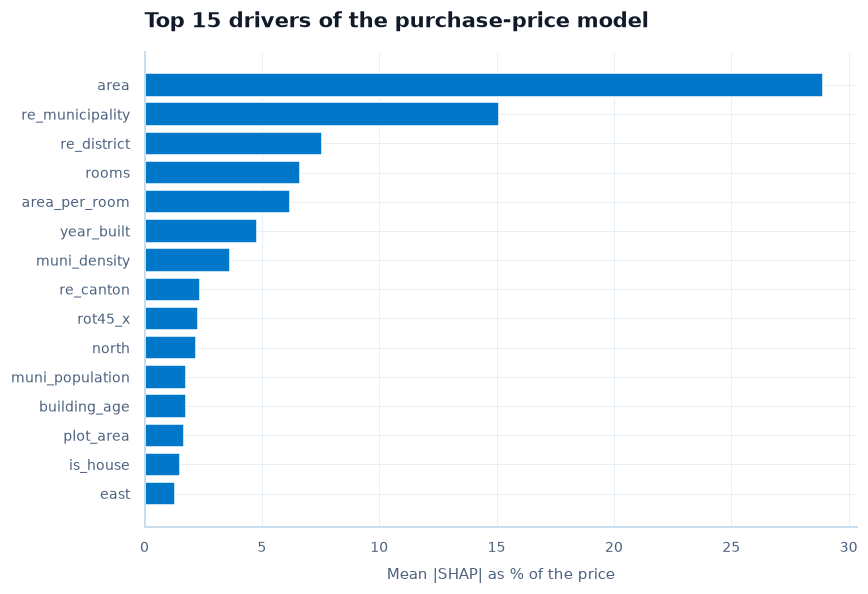

In [12]:
explanation = models.tree_shap(lgb_point, X_test, max_rows=BUDGET["shap_rows"])
importance = (pd.Series(np.abs(explanation.values).mean(axis=0), index=explanation.feature_names)
              .sort_values().tail(15))
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importance.index, 100 * (np.exp(importance) - 1), color=COLORS["primary"])
ax.set(xlabel="Mean |SHAP| as % of the price", title="Top 15 drivers of the purchase-price model")
fig.tight_layout()
save_fig(fig, "buy_shap_importance")
plt.show()

## 10. Error Analysis by Segment

Errors of the LightGBM-TE point model on the test set by category, price quartile, language
region and data quality (area from the GWR, location enrichment). The CHF/m² outliers set aside
in section 2 are scored as an unfiltered check.

In [13]:
pred = pred_test["lgbm_te"]
segments = {
    "category": test_df["property_category"],
    "price quartile": pd.qcut(test_df["price"], 4, labels=["Q1", "Q2", "Q3", "Q4"]),
    "language region": test_df["lang_region"],
    "area source": test_df["area_source"].fillna("missing"),
    "EGID found": test_df["egid"].notna().map({True: "yes", False: "no"}),
}
seg_table = pd.concat({name: evaluation.segment_metrics(y_test, pred, seg.to_numpy())
                       for name, seg in segments.items()})
ape = pd.Series(np.abs(pred - y_test) / y_test, index=test_df.index)
seg_table["MdAPE"] = [100 * ape[seg.to_numpy() == key].median()
                      for name, seg in segments.items() for key in seg_table.loc[name].index]
write_table(seg_table.reset_index(names=["segment", "value"]), "buy_error_segments", ".3g")
display(seg_table.round(1))
X_out = encoder.transform(df_outliers.pipe(data.add_engineered_features).assign(
    is_house=lambda d: d["property_category"].eq("house").astype(float)))
out_pred = np.exp(lgb_point.predict(X_out))
print(f"CHF/m² outliers ({len(df_outliers)}): MdAPE "
      f"{100 * np.median(np.abs(out_pred - df_outliers['price']) / df_outliers['price']):.1f} % "
      f"vs {100 * ape.median():.1f} % on the test set")

n       MAE       RMSE  MAPE      bias  MdAPE
                segment                                                    
category        apartment  3506  187852.7   387448.5  15.8  -23075.2   11.2
                house      2053  372742.4   849129.1  20.8  -44183.8   15.0
price quartile  Q1         1398   95190.7   142641.8  20.4   52886.3   12.6
                Q2         1382  127197.9   189443.9  15.4   50019.8   10.6
                Q3         1396  186812.3   254416.4  15.2    3489.2   11.6
                Q4         1383  617641.0  1152870.4  19.7 -231051.7   15.5
language region de         2172  215047.5   369330.7  17.1  -32490.3   12.2
                fr         2449  288746.9   773513.9  16.9  -27759.0   11.5
                it          938  266127.1   511066.7  21.3  -35245.8   15.0
area source     gwr         155  267386.5   410509.4  25.4  -82634.6   19.3
                listing    5404  255811.7   605373.5  17.5  -29386.2   12.1
EGID found      no         2881  302618.6   747695.2  18.0  -30926.2   12.8
                yes        2678  206126.7   384513.9  17.3  -30811.4   12.1

CHF/m² outliers (683): MdAPE 71.5 % vs 12.4 % on the test set


**Interpretation.** Expensive objects (Q4) and houses carry the largest absolute errors, the
percentage errors show whether they are also relatively worse. If objects whose area came from
the GWR or without an EGID have clearly larger errors, those data-quality flags are where better
enrichment pays off.

## 11. Model Bundle and Summary

The point model, quantile model and calibrator go into one `RentModelBundle` (the class is
generic) at `models/buy_bundle_v1.joblib`, so a later app page can serve purchase estimates with
`intervals.predict_frame` without retraining.

In [14]:
summary = pd.DataFrame({n: metrics_row(y_test, p) for n, p in pred_test.items()}).T
summary["cv_mae"] = [evaluation.METRICS["MAE"](y_train, cv_oof[n]) for n in summary.index]
write_table(summary.reset_index(names="model"), "buy_model_comparison",
            {"MAE": ".0f", "RMSE": ".0f", "MedAE": ".0f", "MAPE": ".1f", "R2": ".3f",
             "MdAPE": ".1f", "within_10pct": ".3f", "cv_mae": ".0f"},
            note=f"session {SESSION_ID}, run {RUN_MODE}, {len(test_df):,} test objects")
display(summary.round(3))
selected = summary["cv_mae"].idxmin()
bundle = intervals.RentModelBundle(
    encoder=encoder, point_model=lgb_point, quantile_model=qmodel, calibrator=mondrian,
    band_cutpoints=band_cutpoints,
    metadata={"version": "buy_bundle_v1", "target": "asking purchase price (CHF)",
              "session": SESSION_ID, "run_mode": RUN_MODE, "data_source": DATA_USED,
              "feature_cols": F_LGB, "group_cols": GROUP_COLS,
              "test_metrics_point": metrics_row(y_test, pred_test["lgbm_te"]),
              "selected_by_cv": selected,
              "disclaimer": "Estimate of current asking prices; not a valuation."})
bundle.save(BUNDLE_PATH)
check = intervals.predict_frame(intervals.RentModelBundle.load(BUNDLE_PATH), test_df.iloc[:50])
assert np.allclose(check["expected"], pred_test["lgbm_te"][:50])
best = summary.loc["lgbm_te"]
print(f"LightGBM-TE: test MAE {best['MAE']:,.0f} CHF, MdAPE {best['MdAPE']:.1f} %, "
      f"{best['within_10pct']:.0%} within ±10 %, R² {best['R2']:.3f}; lowest CV MAE: {selected}; "
      f"80 % interval coverage {cov.loc[('Mondrian CQR', 'all'), 'coverage']:.1%}; "
      f"saved {BUNDLE_PATH.name}")

,MAE,RMSE,MedAE,MAPE,R2,MdAPE,within_10pct,cv_mae
naive,319891.836,680429.858,163508.772,23.624,0.737,16.692,0.329,330964.338
lgbm_tab,326602.940,710692.853,163202.508,23.180,0.713,17.312,0.308,330196.592
lgbm_te,256134.480,600797.332,122155.974,17.689,0.795,12.360,0.420,260504.040
lgbm_te+t,242692.301,577876.395,117628.057,16.720,0.810,11.932,0.434,254793.253
lgbm_te+p,241441.433,577568.970,114123.097,16.553,0.810,11.721,0.443,251600.221


LightGBM-TE: test MAE 256,134 CHF, MdAPE 12.4 %, 42% within ±10 %, R² 0.795; lowest CV MAE: lgbm_te+p; 80 % interval coverage 80.2%; saved buy_bundle_v1.joblib


**Conclusion and limits.**

- Asking prices, not transaction prices; one snapshot (late October 2026), so no drift test.
- The bundle serves the LightGBM-TE model without text or portal fields (like the rent app);
  section 7 shows what text and portal attributes would add.
- Houses depend on the plot, which only part of the listings state (`plot_area`); the GWR has no
  plot size. A cadastral join (parcel area) would be the next enrichment step.
- A natural follow-up is a **price-to-rent ratio** per municipality from this model and the rent
  model (`rent_bundle_v2`), e.g. for the QoLI value score.